
# JATIKARYA
## Image Provenance Verification after Generative Editing Using Watermarks and Visual Matching

**Program:** Magister Sistem Informasi  
**Bidang:** Artificial Intelligence / Computer Vision  
**Jenis:** Penelitian individu S2  
**Platform:** Python & Google Colab  
**Target publikasi:** Minimal SINTA 2, aspirasi standar Scopus

### Tujuan Penelitian
Mengembangkan dan mengevaluasi sistem verifikasi asal gambar setelah pengeditan generatif menggunakan dua pendekatan:

1. **TrustMark:** Invisible watermarking untuk menyisipkan dan memeriksa identitas gambar.
2. **DINOv2:** Visual feature extraction untuk mencocokkan gambar dengan sumber terdaftar.

### Metode Evaluasi
- TrustMark-only
- DINOv2-only
- Naive Fusion
- Calibrated Fusion dengan conflict handling dan abstention

### Prinsip Penelitian
- Tidak membuat data atau hasil eksperimen palsu.
- Semua eksperimen harus dapat direproduksi.
- Pisahkan dataset development, calibration, dan final test.
- Catat konfigurasi, versi model, dan hasil pengujian.
- Tidak menyimpulkan novelty tanpa audit literatur.
- Semua keputusan penting memerlukan persetujuan peneliti.

### Status Awal
- Literature Verification: Belum ditutup
- Research Methodology: Draf v0.1
- Notebook 01: Persiapan lingkungan
- Eksperimen: Belum dijalankan
- Hasil penelitian: Belum tersedia


In [ ]:
# SEL 1 - MOUNT DRIVE
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW")
OUT  = BASE / "07_ANALYSIS_V2"      # folder khusus hasil baru
OUT.mkdir(exist_ok=True)
print("Hasil baru akan disimpan di:", OUT)

Mounted at /content/drive
Hasil baru akan disimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2


In [ ]:
# SEL 2 - CEK FOLDER DISTRAKTOR
from collections import Counter
DIST = BASE.parent / "08_DISTRACTORS"      # satu tingkat di atas JATIKARYA_NEW
allf = [p for p in DIST.rglob("*") if p.is_file()]
print("Total file:", len(allf))
print(Counter(p.suffix.lower() for p in allf))

Total file: 120
Counter({'.jpg': 120})


In [ ]:
import pandas as pd, numpy as np, json
from sklearn.metrics import roc_auc_score

# 1. Temukan file hasil DINOv2 (hanya dibaca)
files = list((BASE / "02_EXPERIMENTS/STEP_11F_DINOV2_GENERATIVE").glob(
    "RUN_*/outputs/dinov2_240_results.csv"))
assert len(files) == 1, f"Ditemukan {len(files)} file, periksa manual"
df = pd.read_csv(files[0])
print("Baris:", len(df), "| split:", df.split.value_counts().to_dict())

s1 = df.similarity_top1.astype(float)
m  = df.margin_top1_top2.astype(float)
correct = df.source_id == df.predicted_source_id

# 2. Genuine = skor sumber benar (hanya top-1 benar)
#    Impostor = kandidat terbaik setelah sumber benar dibuang dari galeri
df["genuine"]  = np.where(correct, s1, np.nan)
df["impostor"] = np.where(correct, s1 - m, s1)

cal = df[df.split == "CALIBRATION"]
fin = df[df.split == "FINAL_TEST"]

# 3. Ambang dari CALIBRATION saja (pertahankan 95% genuine)
thr = np.quantile(cal.genuine.dropna(), 0.05)

def rates(d):
    g = d.genuine.dropna()
    return (g < thr).mean(), (d.impostor >= thr).mean()   # FRR, FAR

frr, far = rates(fin)
y  = np.r_[np.ones(fin.genuine.notna().sum()), np.zeros(len(fin))]
sc = np.r_[fin.genuine.dropna().values, fin.impostor.values]
auc = roc_auc_score(y, sc)

# 4. Bootstrap per SUMBER
rng = np.random.default_rng(0)
srcs = fin.source_id.unique()
boot = np.array([
    rates(pd.concat([fin[fin.source_id == s]
                     for s in rng.choice(srcs, len(srcs), replace=True)]))
    for _ in range(2000)
])
ci = {n: np.percentile(boot[:, i], [2.5, 97.5]).round(3).tolist()
      for i, n in enumerate(["FRR", "FAR"])}

hasil = {"threshold": round(float(thr), 4), "FRR": round(float(frr), 4),
         "FAR": round(float(far), 4), "AUC": round(float(auc), 4),
         "CI95": ci, "n_final": int(len(fin)), "n_sources_final": int(len(srcs))}
print(json.dumps(hasil, indent=2))

# 5. Simpan HANYA ke folder baru
(OUT / "openset_from_existing_scores.json").write_text(
    json.dumps(hasil, indent=2), encoding="utf-8")
print("Tersimpan di:", OUT / "openset_from_existing_scores.json")

Baris: 240 | split: {'CALIBRATION': 120, 'FINAL_TEST': 120}
{
  "threshold": 0.3721,
  "FRR": 0.0167,
  "FAR": 0.4083,
  "AUC": 0.9896,
  "CI95": {
    "FRR": [
      0.0,
      0.05
    ],
    "FAR": [
      0.225,
      0.608
    ]
  },
  "n_final": 120,
  "n_sources_final": 20
}
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/openset_from_existing_scores.json


In [ ]:
import pandas as pd, numpy as np

# 1. Baca hasil 11G (berisi TrustMark + DINOv2 per gambar)
g11 = sorted((BASE / "02_EXPERIMENTS/STEP_11G_NAIVE_FUSION").glob(
    "RUN_*/outputs/naive_fusion_240_results.csv"))
assert g11, "File 11G tidak ditemukan"
df = pd.read_csv(g11[-1], dtype=str, keep_default_na=False)

need = {"split","tm_source_prediksi","dino_source_prediksi",
        "source_id_sebenarnya","similarity_top1","margin_top1_top2"}
assert need.issubset(df.columns), f"Kolom kurang: {need - set(df.columns)}"

s1 = pd.to_numeric(df.similarity_top1)
m  = pd.to_numeric(df.margin_top1_top2)
correct = df.dino_source_prediksi == df.source_id_sebenarnya
df["genuine"]  = np.where(correct, s1, np.nan)
df["impostor"] = np.where(correct, s1 - m, s1)
df["tm_ada"]   = df.tm_source_prediksi != ""
df["tm_benar"] = df.tm_source_prediksi == df.source_id_sebenarnya

cal = df[df.split == "CALIBRATION"]
fin = df[df.split == "FINAL_TEST"]

def rates(d, thr):
    g = d.genuine.dropna()
    return (g < thr).mean(), (d.impostor >= thr).mean()   # FRR, FAR

def boot_ci(d, thr, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    srcs = d.source_id_sebenarnya.unique()
    out = np.array([
        rates(pd.concat([d[d.source_id_sebenarnya == s]
              for s in rng.choice(srcs, len(srcs), replace=True)]), thr)
        for _ in range(n)])
    return np.percentile(out, [2.5, 97.5], axis=0).round(3)

# 2. Ambang dari target FAR pada CALIBRATION, diuji di FINAL_TEST
rows = []
for far_t in [0.01, 0.05, 0.10, 0.20]:
    thr = float(np.quantile(cal.impostor, 1 - far_t))
    frr, far = rates(fin, thr)
    ci = boot_ci(fin, thr)
    # 3. Kasus yang ditolak DINOv2 saja tetapi TrustMark benar -> diselamatkan fusion
    rescued = int((fin.tm_ada & fin.tm_benar & (fin.genuine < thr)).sum())
    rows.append({"FAR_target": far_t, "ambang": round(thr, 3),
                 "FRR_final": round(frr, 3), "FRR_CI": ci[:, 0].tolist(),
                 "FAR_final": round(far, 3), "FAR_CI": ci[:, 1].tolist(),
                 "diselamatkan_TrustMark": rescued})

hasil = pd.DataFrame(rows)
print(hasil.to_string(index=False))
print("\nFINAL_TEST: gambar dengan payload TrustMark benar =",
      int((fin.tm_ada & fin.tm_benar).sum()), "dari", len(fin))

hasil.to_csv(OUT / "threshold_by_target_far.csv", index=False)
print("Tersimpan di:", OUT / "threshold_by_target_far.csv")

 FAR_target  ambang  FRR_final      FRR_CI  FAR_final         FAR_CI  diselamatkan_TrustMark
       0.01   0.466      0.017 [0.0, 0.05]      0.150 [0.008, 0.325]                       0
       0.05   0.424      0.017 [0.0, 0.05]      0.208 [0.067, 0.383]                       0
       0.10   0.389      0.017 [0.0, 0.05]      0.367 [0.192, 0.567]                       0
       0.20   0.336      0.017 [0.0, 0.05]      0.500 [0.308, 0.692]                       0

FINAL_TEST: gambar dengan payload TrustMark benar = 14 dari 120
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/threshold_by_target_far.csv


In [ ]:
import pandas as pd, numpy as np

# 1. Muat ranking 9600 skor (40 kandidat x 240 gambar)
rk_path = sorted((BASE / "02_EXPERIMENTS/STEP_11F_DINOV2_GENERATIVE").glob(
    "RUN_*/outputs/all_candidate_rankings_9600.csv"))[-1]
rk = pd.read_csv(rk_path, dtype=str, keep_default_na=False)
print("Kolom ranking:", list(rk.columns))

def pick(*opts):
    for o in opts:
        if o in rk.columns: return o
    raise KeyError(f"Kolom tidak ditemukan dari {opts}. Kirim daftar kolom di atas.")

c_true  = pick("source_id_gambar_edit", "source_id_sebenarnya", "source_id")
c_cand  = pick("source_id_kandidat", "candidate_source_id")
c_score = pick("cosine_similarity", "similarity")
c_img   = pick("image_sha256")

rk[c_score] = pd.to_numeric(rk[c_score])

# 2. Skor tertinggi dari kandidat YANG BUKAN sumber benar, per gambar
imp = rk[rk[c_true] != rk[c_cand]]
idx = imp.groupby(c_img)[c_score].idxmax()
best = imp.loc[idx, [c_img, c_true, c_cand, c_score]].rename(
    columns={c_true: "sumber_benar", c_cand: "peniru", c_score: "skor_peniru"})

# 3. Tambahkan split dan nomor sumber dari hasil 11G
g11 = sorted((BASE / "02_EXPERIMENTS/STEP_11G_NAIVE_FUSION").glob(
    "RUN_*/outputs/naive_fusion_240_results.csv"))[-1]
d = pd.read_csv(g11, dtype=str, keep_default_na=False)
num = d.drop_duplicates("source_id_sebenarnya").set_index(
    "source_id_sebenarnya")["source_number"].to_dict()
split = d.set_index("image_sha256")["split"].to_dict() if "image_sha256" in d.columns else {}

best["split"] = best[c_img].map(split)
best["no_benar"] = best.sumber_benar.map(num)
best["no_peniru"] = best.peniru.map(num)

fin = best[best.split == "FINAL_TEST"]

# 4. Pasangan yang paling membingungkan (maks per pasangan)
pair = (fin.groupby(["no_benar", "no_peniru"]).skor_peniru.max()
        .sort_values(ascending=False).head(10).round(3))
print("\nPasangan FINAL_TEST paling membingungkan (nomor sumber 01-40):")
print(pair.to_string())

thr = 0.466
print(f"\nGambar FINAL_TEST dengan skor peniru >= {thr}:",
      int((fin.skor_peniru >= thr).sum()), "dari", len(fin))
print("Dari sumber:", sorted(fin[fin.skor_peniru >= thr].no_benar.unique()))

best.to_csv(OUT / "impostor_pairs.csv", index=False)
print("Tersimpan di:", OUT / "impostor_pairs.csv")

Kolom ranking: ['provider', 'source_number', 'source_id', 'split', 'edit_type', 'image_sha256', 'candidate_source_number', 'candidate_source_id', 'rank', 'cosine_similarity', 'is_true_source']

Pasangan FINAL_TEST paling membingungkan (nomor sumber 01-40):
no_benar  no_peniru
21        33           0.577
33        21           0.559
27        21           0.546
28        25           0.506
10        08           0.457
25        28           0.440
03        04           0.438
28        36           0.435
03        35           0.428
36        28           0.424

Gambar FINAL_TEST dengan skor peniru >= 0.466: 18 dari 120
Dari sumber: ['21', '27', '28', '33']
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/impostor_pairs.csv


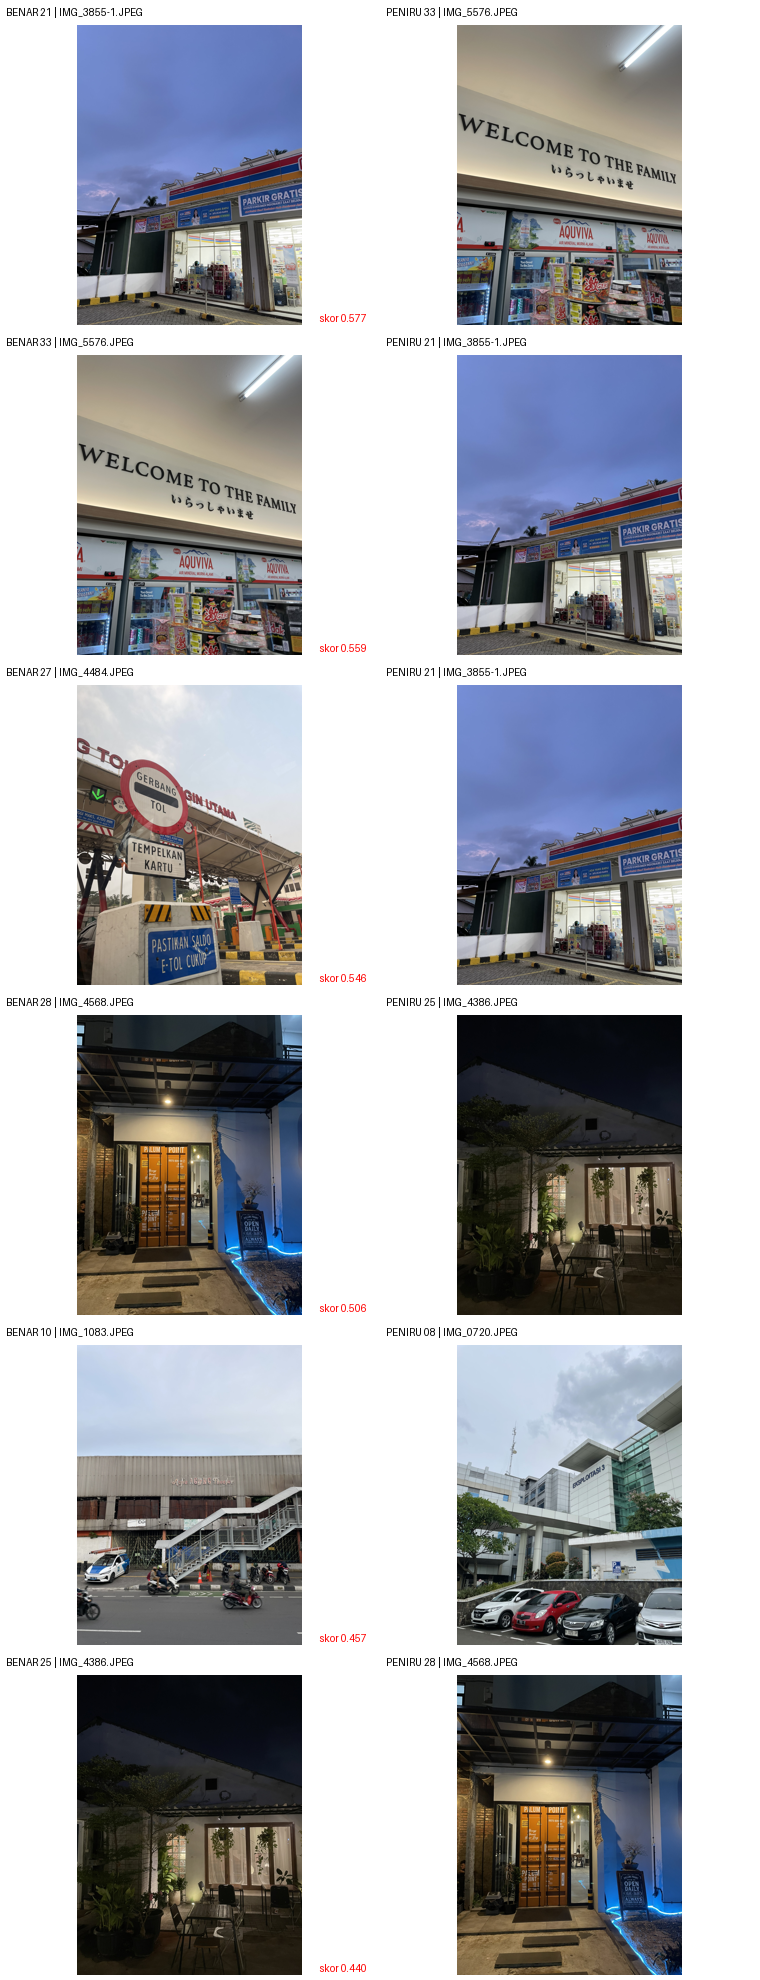

Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/top_confusable_pairs.jpg


In [ ]:
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

# 1. Manifest STEP 11A -> lokasi foto asli per nomor sumber
man = sorted((BASE / "02_EXPERIMENTS/STEP_11A_INDEPENDENT_SOURCE_SPLIT").glob(
    "*/outputs/source_split_manifest.csv"))[-1]
m = pd.read_csv(man, dtype=str, keep_default_na=False)
m["source_number"] = m["source_number"].str.zfill(2)
by_no = m.set_index("source_number")

# 2. Pasangan paling membingungkan di FINAL_TEST
bp = pd.read_csv(OUT / "impostor_pairs.csv",
                 dtype={"no_benar": str, "no_peniru": str})
bp["no_benar"] = bp.no_benar.str.zfill(2)
bp["no_peniru"] = bp.no_peniru.str.zfill(2)
top = (bp[bp.split == "FINAL_TEST"]
       .groupby(["no_benar", "no_peniru"]).skor_peniru.max()
       .sort_values(ascending=False).head(6).reset_index())

def muat(no):
    r = by_no.loc[no]
    with Image.open(BASE / r.stored_path) as im:
        im.seek(0)
        im = ImageOps.exif_transpose(im).convert("RGB")
    return ImageOps.contain(im, (360, 300)), r.original_filename

# 3. Susun lembar: kiri = sumber benar, kanan = peniru
W, H, HEAD = 380, 330, 30
sheet = Image.new("RGB", (W * 2, H * len(top)), "white")
d = ImageDraw.Draw(sheet)
for i, row in top.iterrows():
    for j, no in enumerate([row.no_benar, row.no_peniru]):
        im, fn = muat(no)
        x, y = j * W, i * H
        sheet.paste(im, (x + (W - im.width) // 2, y + 25))
        d.text((x + 6, y + 6),
               f"{'BENAR' if j == 0 else 'PENIRU'} {no} | {fn[:28]}",
               fill="black")
    d.text((W - 60, i * H + H - 18), f"skor {row.skor_peniru:.3f}", fill="red")

sheet.save(OUT / "top_confusable_pairs.jpg", quality=90)
display(sheet)
print("Tersimpan di:", OUT / "top_confusable_pairs.jpg")

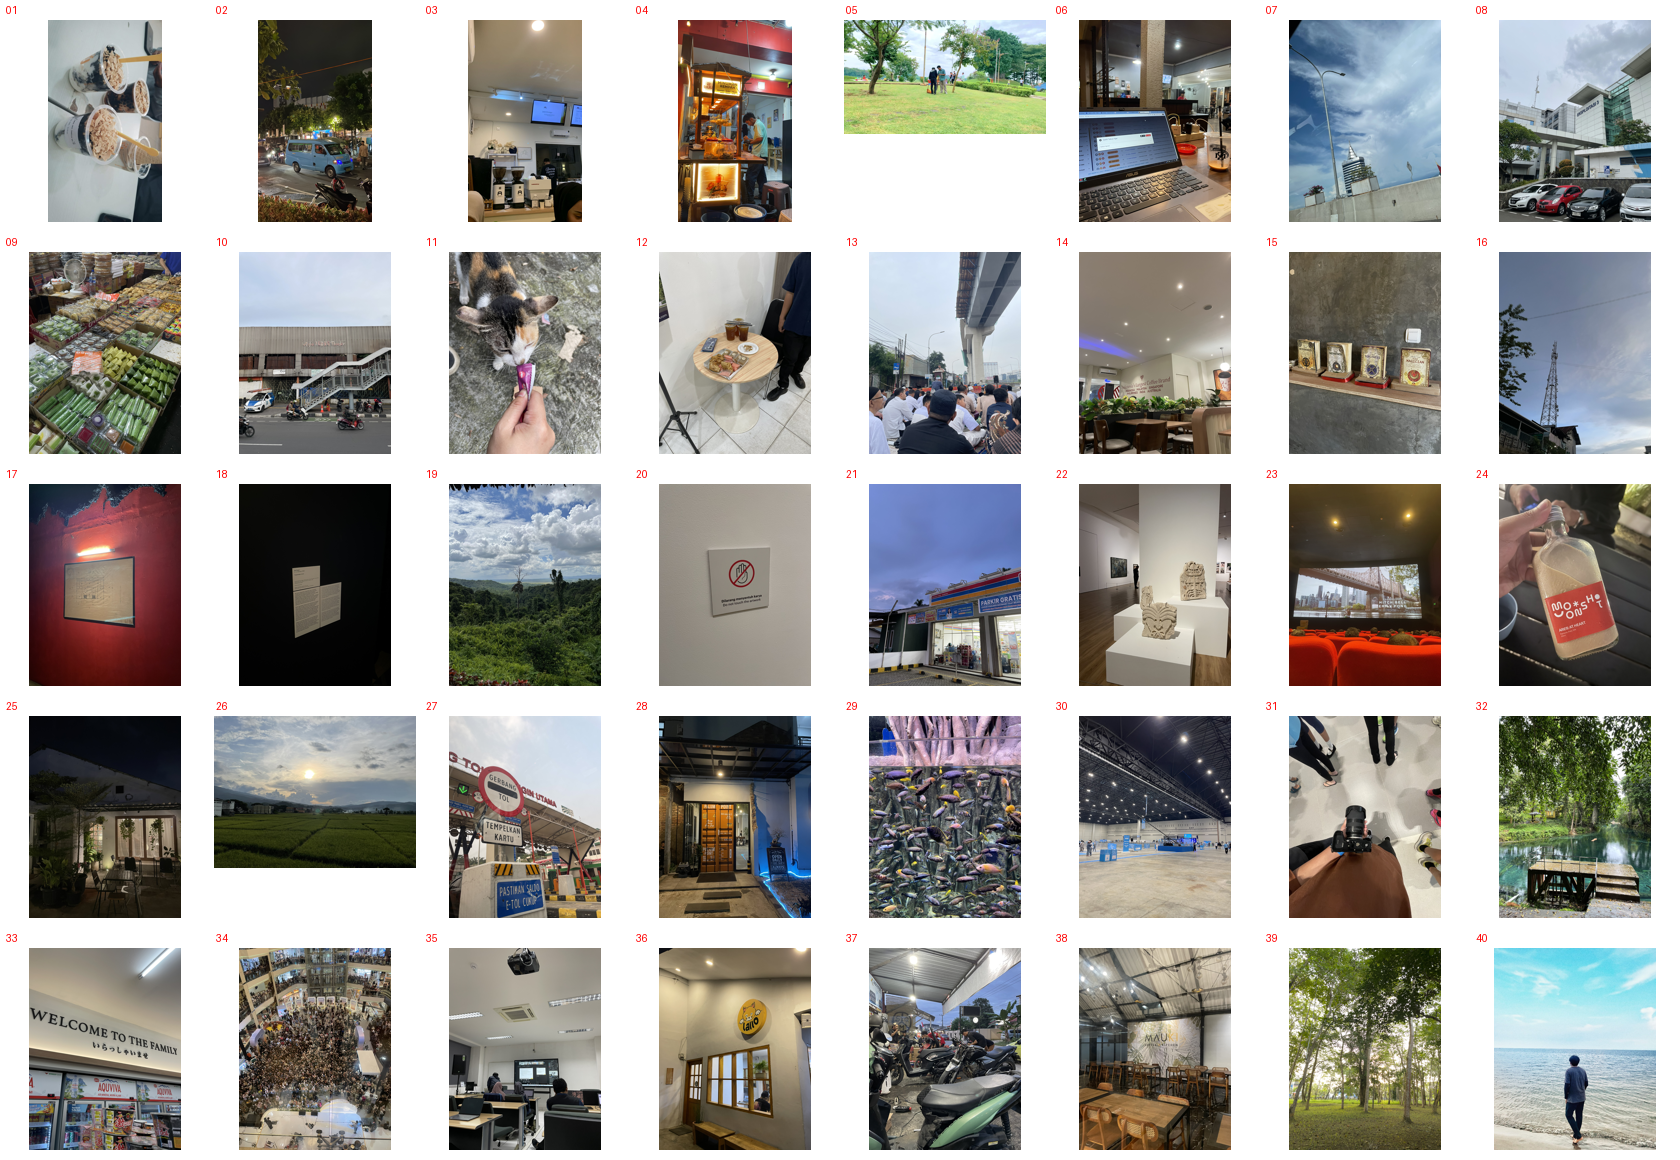

Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/contact_sheet_40_sources.jpg


In [ ]:
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

man = sorted((BASE / "02_EXPERIMENTS/STEP_11A_INDEPENDENT_SOURCE_SPLIT").glob(
    "*/outputs/source_split_manifest.csv"))[-1]
m = pd.read_csv(man, dtype=str, keep_default_na=False)
m["source_number"] = m["source_number"].str.zfill(2)
m = m.sort_values("source_number").reset_index(drop=True)

COLS, T = 8, 210
rows = -(-len(m) // COLS)
sheet = Image.new("RGB", (COLS * T, rows * (T + 22)), "white")
d = ImageDraw.Draw(sheet)

for i, r in m.iterrows():
    with Image.open(BASE / r.stored_path) as im:
        im.seek(0)
        im = ImageOps.exif_transpose(im).convert("RGB")
    im = ImageOps.contain(im, (T - 8, T - 8))
    x, y = (i % COLS) * T, (i // COLS) * (T + 22)
    sheet.paste(im, (x + (T - im.width) // 2, y + 20))
    d.text((x + 6, y + 4), r.source_number, fill="red")

sheet.save(OUT / "contact_sheet_40_sources.jpg", quality=88)
display(sheet)
print("Tersimpan di:", OUT / "contact_sheet_40_sources.jpg")

In [ ]:
# SEL 3 - BASELINE (siapkan variabel)
%pip -q install imagehash
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from PIL import Image, ImageOps
from torchvision import transforms
from sklearn.metrics import roc_auc_score
import imagehash
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

def load(p):
    with Image.open(p) as im:
        im.seek(0)
        return ImageOps.exif_transpose(im).convert("RGB")

# 1. Sumber (40) dan query generatif (240)
sm = sorted((BASE / "02_EXPERIMENTS/STEP_11A_INDEPENDENT_SOURCE_SPLIT").glob(
    "*/outputs/source_split_manifest.csv"))[-1]
S = pd.read_csv(sm, dtype=str, keep_default_na=False)
S["source_number"] = S.source_number.str.zfill(2)
S = S.sort_values("source_number").reset_index(drop=True)
assert len(S) == 40

G = pd.read_csv(BASE / "02_EXPERIMENTS/STEP_11D_FINAL_REUPLOAD/"
                "generative_final_manifest_240.csv", dtype=str, keep_default_na=False)
print("Kolom manifest generatif:", list(G.columns))
for c in ("stored_path", "source_number", "split", "provider", "edit_type"):
    assert c in G.columns, f"Kolom '{c}' tidak ada, kirim daftar kolom di atas"
G["source_number"] = G.source_number.str.zfill(2)
assert len(G) == 240

src_imgs = [load(BASE / p) for p in S.stored_path]
qry_imgs = [load(BASE / p) for p in G.stored_path]
true_idx = G.source_number.map({n: i for i, n in enumerate(S.source_number)}).to_numpy()
assert not np.isnan(true_idx.astype(float)).any()

def l2(x): return x / np.linalg.norm(x, axis=1, keepdims=True)

# 2. Pengekstrak fitur
def dino(name, squash):
    model = torch.hub.load("facebookresearch/dinov2", name, trust_repo=True).to(dev).eval()
    rs = transforms.Resize((518, 518)) if squash else transforms.Compose(
        [transforms.Resize(518), transforms.CenterCrop(518)])
    tf = transforms.Compose([rs, transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    def f(imgs):
        out = []
        for i in range(0, len(imgs), 16):
            x = torch.stack([tf(im) for im in imgs[i:i+16]]).to(dev)
            with torch.inference_mode():
                out.append(model(x).float().cpu().numpy())
        return l2(np.concatenate(out))
    return f

clip_m = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
clip_p = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def clip_f(imgs):
    out = []
    for i in range(0, len(imgs), 32):
        inp = clip_p(images=imgs[i:i+32], return_tensors="pt").to(dev)
        with torch.inference_mode():
            o = clip_m.get_image_features(**inp)
            if not torch.is_tensor(o):   # versi baru: ambil vektor dari objek keluaran
                o = o.pooler_output if getattr(o, "pooler_output", None) is not None \
                    else o.last_hidden_state[:, 0]
            out.append(o.float().cpu().numpy())
    return l2(np.concatenate(out))

def phash_sim(q, s):
    h = lambda im: np.array(imagehash.phash(im, hash_size=16).hash, dtype=bool).ravel()
    Hq, Hs = np.stack([h(i) for i in q]), np.stack([h(i) for i in s])
    return (Hq[:, None, :] == Hs[None, :, :]).mean(-1)

methods = {
    "pHash": lambda: phash_sim(qry_imgs, src_imgs),
    "CLIP-B32": lambda: (lambda fs: clip_f(qry_imgs) @ fs.T)(clip_f(src_imgs)),
    "DINOv2-S crop (lama)": lambda: (lambda f: f(qry_imgs) @ f(src_imgs).T)(dino("dinov2_vits14", False)),
    "DINOv2-S tanpa crop": lambda: (lambda f: f(qry_imgs) @ f(src_imgs).T)(dino("dinov2_vits14", True)),
    "DINOv2-B tanpa crop": lambda: (lambda f: f(qry_imgs) @ f(src_imgs).T)(dino("dinov2_vitb14", True)),
}

# 3. Evaluasi
fin = (G.split == "FINAL_TEST").to_numpy()
rng = np.random.default_rng(0)
rows, sims = [], {}
for name, fn in methods.items():
    sim = np.asarray(fn(), dtype=float); sims[name] = sim
    r = np.arange(len(sim))
    ok = sim.argmax(1) == true_idx
    gen = sim[r, true_idx]
    msk = sim.copy(); msk[r, true_idx] = -np.inf
    imp = msk.max(1)                     # sumber benar dibuang dari galeri
    def auc(m): return roc_auc_score(np.r_[np.ones(m.sum()), np.zeros(m.sum())],
                                     np.r_[gen[m], imp[m]])
    srcs = G.source_number[fin].unique()
    boots = []
    for _ in range(1000):
        pick = rng.choice(srcs, len(srcs), replace=True)
        idx = np.concatenate([np.where(fin & (G.source_number == s).to_numpy())[0] for s in pick])
        boots.append(ok[idx].mean())
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append({"metode": name, "top1_240": f"{ok.sum()}/240",
                 "top1_final": f"{ok[fin].sum()}/{fin.sum()}",
                 "top1_final_CI95": [round(lo, 3), round(hi, 3)],
                 "AUC_openset_final": round(auc(fin), 3),
                 "AUC_openset_all": round(auc(np.ones(len(G), bool)), 3)})
    print("selesai:", name)

res = pd.DataFrame(rows)
print(res.to_string(index=False))
res.to_csv(OUT / "baseline_comparison.csv", index=False)
np.savez_compressed(OUT / "baseline_similarity_matrices.npz", **{k: v for k, v in sims.items()})
print("Tersimpan di:", OUT)

Device: cuda
Kolom manifest generatif: ['provider', 'source_number', 'source_id', 'split', 'edit_type', 'original_filename', 'sha256', 'actual_format', 'width', 'height', 'stored_path', 'source_filename', 'parent_watermarked_sha256', 'label_evidence']


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (14 outputs left out)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:05<00:00, 57.8MB/s]


selesai: DINOv2-B tanpa crop
              metode top1_240 top1_final top1_final_CI95  AUC_openset_final  AUC_openset_all
               pHash  232/240    116/120      [0.9, 1.0]              0.967            0.967
            CLIP-B32  237/240    118/120     [0.95, 1.0]              0.975            0.985
DINOv2-S crop (lama)  238/240    120/120      [1.0, 1.0]              0.990            0.974
 DINOv2-S tanpa crop  239/240    120/120      [1.0, 1.0]              0.992            0.977
 DINOv2-B tanpa crop  237/240    120/120      [1.0, 1.0]              0.985            0.968
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2


In [ ]:
# SEL 4 - KURVA UKURAN GALERI (DISTRAKTOR)
import hashlib

DIST = BASE.parent / "08_DISTRACTORS"      # lokasi yang benar (terbukti di SEL 2)
exts = {".jpg", ".jpeg", ".png", ".webp"}
files = sorted(p for p in DIST.rglob("*") if p.suffix.lower() in exts)
print("Folder distraktor:", DIST)
print("File ditemukan:", len(files))
assert len(files) >= 50, "Letakkan minimal 50 foto di 08_DISTRACTORS"

src_hash = {hashlib.sha256((BASE / p).read_bytes()).hexdigest() for p in S.stored_path}
dist_imgs, skipped = [], 0
for p in files:
    try:
        if hashlib.sha256(p.read_bytes()).hexdigest() in src_hash:
            skipped += 1; continue
        dist_imgs.append(load(p))
    except Exception:
        skipped += 1
nd = len(dist_imgs)
print("Dipakai:", nd, "| dilewati:", skipped)

gal = src_imgs + dist_imgs          # 40 sumber pertama, lalu distraktor

def sim_full(name):
    if name == "pHash":
        return phash_sim(qry_imgs, gal)
    if name == "CLIP-B32":
        return clip_f(qry_imgs) @ clip_f(gal).T
    f = dino("dinov2_vitb14" if "-B" in name else "dinov2_vits14", "tanpa crop" in name)
    return f(qry_imgs) @ f(gal).T

names = ["pHash", "CLIP-B32", "DINOv2-S crop (lama)",
         "DINOv2-S tanpa crop", "DINOv2-B tanpa crop"]
full = {}
for n in names:
    full[n] = np.asarray(sim_full(n), dtype=float)
    print("selesai:", n)

sizes = sorted({0} | {k for k in (25, 50, 100, 200, 400, nd) if k <= nd})
rng = np.random.default_rng(0)
rows = []
for n in names:
    for k in sizes:
        accs = []
        for _ in range(1 if k in (0, nd) else 10):
            cols = np.r_[np.arange(40), 40 + rng.choice(nd, k, replace=False)]
            accs.append((full[n][:, cols].argmax(1) == true_idx).mean())
        rows.append({"metode": n, "galeri": 40 + k,
                     "top1": round(float(np.mean(accs)), 4),
                     "sd": round(float(np.std(accs)), 4)})
res2 = pd.DataFrame(rows)
print(res2.pivot(index="galeri", columns="metode", values="top1").round(3).to_string())
res2.to_csv(OUT / "gallery_scaling.csv", index=False)
print("Tersimpan di:", OUT / "gallery_scaling.csv")

Folder distraktor: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/08_DISTRACTORS
File ditemukan: 120
Dipakai: 120 | dilewati: 0
selesai: pHash
selesai: CLIP-B32


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S crop (lama)


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S tanpa crop


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-B tanpa crop
metode  CLIP-B32  DINOv2-B tanpa crop  DINOv2-S crop (lama)  DINOv2-S tanpa crop  pHash
galeri                                                                                 
40         0.988                0.988                 0.992                0.996  0.967
65         0.988                0.987                 0.988                0.991  0.967
90         0.988                0.985                 0.986                0.990  0.967
140        0.988                0.983                 0.984                0.988  0.967
160        0.988                0.983                 0.983                0.988  0.967
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/gallery_scaling.csv


In [ ]:
# SEL 5 - OPEN-SET DENGAN QUERY ASING NYATA (120 foto distraktor sebagai query)
def mp(imgs):
    return float(np.median([w * h for w, h in (i.size for i in imgs)]) / 1e6)
print(f"Median megapiksel -> sumber: {mp(src_imgs):.2f} | "
      f"query edit AI: {mp(qry_imgs):.2f} | distraktor: {mp(dist_imgs):.2f}")

def sim_pair(name, A, B):
    if name == "pHash":
        return phash_sim(A, B)
    if name == "CLIP-B32":
        return clip_f(A) @ clip_f(B).T
    f = dino("dinov2_vitb14" if "-B" in name else "dinov2_vits14", "tanpa crop" in name)
    return f(A) @ f(B).T

cal = (G.split == "CALIBRATION").to_numpy()
fin = (G.split == "FINAL_TEST").to_numpy()
r = np.arange(len(G))
rng = np.random.default_rng(0)
rows = []
for n in names:
    gen = full[n][r, true_idx]                                   # skor sumber yang benar
    foreign = np.asarray(sim_pair(n, dist_imgs, src_imgs), float).max(1)  # query asing vs 40 sumber
    for ret in (0.95, 0.99):
        thr = float(np.quantile(gen[cal], 1 - ret))              # ambang hanya dari CALIBRATION
        frr = float((gen[fin] < thr).mean())
        far = float((foreign >= thr).mean())
        boots = [(foreign[rng.integers(0, len(foreign), len(foreign))] >= thr).mean()
                 for _ in range(1000)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append({"metode": n, "retensi_genuine_CAL": ret, "ambang": round(thr, 3),
                     "FRR_final": round(frr, 3), "FAR_asing": round(far, 3),
                     "FAR_CI95": [round(lo, 3), round(hi, 3)]})
    print("selesai:", n)

res3 = pd.DataFrame(rows)
print(res3.to_string(index=False))
res3.to_csv(OUT / "openset_real_foreign_queries.csv", index=False)
print("Tersimpan di:", OUT / "openset_real_foreign_queries.csv")

Median megapiksel -> sumber: 3.15 | query edit AI: 1.57 | distraktor: 1.23
selesai: pHash
selesai: CLIP-B32


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S crop (lama)


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S tanpa crop


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-B tanpa crop
              metode  retensi_genuine_CAL  ambang  FRR_final  FAR_asing       FAR_CI95
               pHash                 0.95   0.654      0.042      0.000     [0.0, 0.0]
               pHash                 0.99   0.457      0.008      1.000     [1.0, 1.0]
            CLIP-B32                 0.95   0.830      0.083      0.000     [0.0, 0.0]
            CLIP-B32                 0.99   0.752      0.025      0.008   [0.0, 0.025]
DINOv2-S crop (lama)                 0.95   0.353      0.017      0.208 [0.133, 0.283]
DINOv2-S crop (lama)                 0.99   0.162      0.000      0.800 [0.725, 0.875]
 DINOv2-S tanpa crop                 0.95   0.407      0.008      0.092 [0.042, 0.142]
 DINOv2-S tanpa crop                 0.99   0.201      0.000      0.692 [0.616, 0.775]
 DINOv2-B tanpa crop                 0.95   0.276      0.017      0.217 [0.142, 0.292]
 DINOv2-B tanpa crop                 0.99   0.146      0.000      0.692 [0.608, 0.767]
Tersimpan di: 

In [ ]:
# SEL 6 - AUC SUMBER ASLI vs FOTO ASING (tanpa ambang) + titik operasi ROC
from sklearn.metrics import roc_auc_score

foreign_scores = {}
for n in names:
    foreign_scores[n] = np.asarray(sim_pair(n, dist_imgs, src_imgs), float).max(1)
    print("selesai:", n)

r = np.arange(len(G))
src_final = G.source_number[fin].to_numpy()
srcs = np.unique(src_final)
idx_by_src = {s: np.where(src_final == s)[0] for s in srcs}
rng = np.random.default_rng(1)

def auc(g, f):
    return roc_auc_score(np.r_[np.ones(len(g)), np.zeros(len(f))], np.r_[g, f])

rows = []
for n in names:
    gen = full[n][r, true_idx]
    fo = foreign_scores[n]
    g_f = gen[fin]
    bs = []
    for _ in range(1000):
        pick = rng.choice(srcs, len(srcs), replace=True)
        gi = np.concatenate([idx_by_src[s] for s in pick])
        fi = rng.integers(0, len(fo), len(fo))
        bs.append(auc(g_f[gi], fo[fi]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    t1, t5 = np.quantile(fo, 0.99), np.quantile(fo, 0.95)   # deskriptif (dari skor asing)
    rows.append({"metode": n,
                 "AUC_final": round(auc(g_f, fo), 3),
                 "AUC_final_CI95": [round(lo, 3), round(hi, 3)],
                 "AUC_semua240": round(auc(gen, fo), 3),
                 "FRR_di_FAR1%": round(float((g_f < t1).mean()), 3),
                 "FRR_di_FAR5%": round(float((g_f < t5).mean()), 3)})

res4 = pd.DataFrame(rows)
print(res4.to_string(index=False))
res4.to_csv(OUT / "auc_genuine_vs_foreign.csv", index=False)
print("Tersimpan di:", OUT / "auc_genuine_vs_foreign.csv")

selesai: pHash
selesai: CLIP-B32


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S crop (lama)


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-S tanpa crop


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


selesai: DINOv2-B tanpa crop
              metode  AUC_final AUC_final_CI95  AUC_semua240  FRR_di_FAR1%  FRR_di_FAR5%
               pHash      0.967   [0.901, 1.0]         0.967         0.033         0.033
            CLIP-B32      0.996   [0.987, 1.0]         0.998         0.017         0.017
DINOv2-S crop (lama)      0.995   [0.983, 1.0]         0.980         0.017         0.017
 DINOv2-S tanpa crop      0.997   [0.992, 1.0]         0.983         0.017         0.017
 DINOv2-B tanpa crop      0.989   [0.966, 1.0]         0.978         0.017         0.017
Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2/auc_genuine_vs_foreign.csv



=== DISTRAKTOR (n=120) ===
Dengan EXIF : 60 | tanpa EXIF: 60
Kamera      : {'': 64, 'OPPO A37f': 37, 'Research In Motion BlackBerry 8320': 7, 'Nokia N73': 3, 'NIKON COOLPIX S220': 3}
Megapiksel  : min 0.05 | median 1.23 | maks 14.16
Ukuran file : min 8 KB | median 150 KB | maks 5545 KB
File < 0.5 MP: 41 | < 100 KB: 49

=== 40 SUMBER (n=40) ===
Dengan EXIF : 37 | tanpa EXIF: 3
Kamera      : {'Apple iPhone 12': 36, '': 4}
Megapiksel  : min 0.92 | median 3.15 | maks 12.19
Ukuran file : min 70 KB | median 734 KB | maks 6156 KB
File < 0.5 MP: 0 | < 100 KB: 1


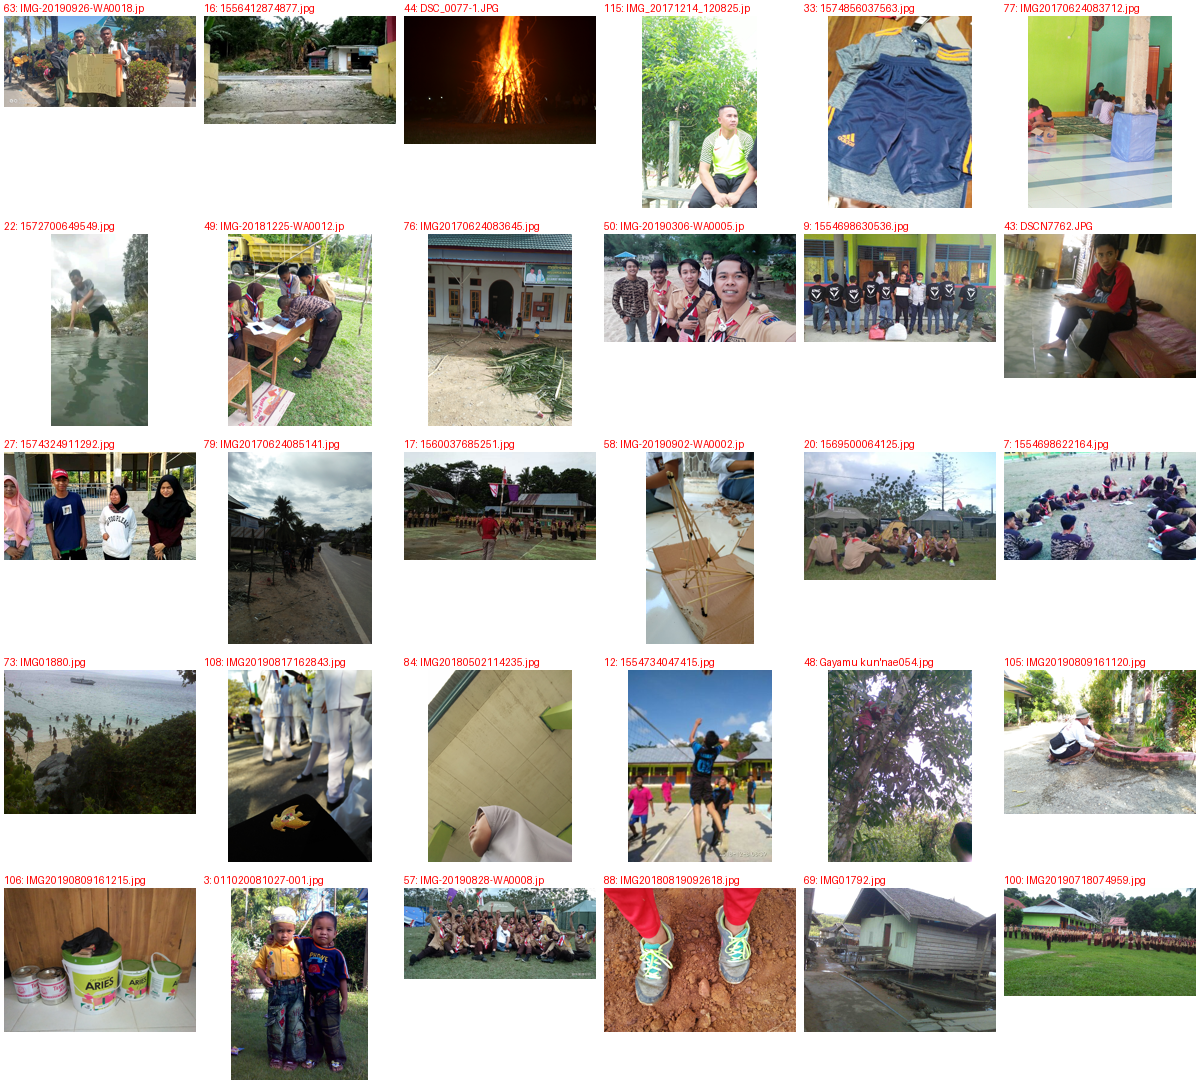


=== 6 gambar genuine dengan skor terendah (DINOv2-S crop (lama)) ===
    provider    edit_type source_number        split  skor_sumber_benar  top1_benar
71   chatgpt  replacement            24  CALIBRATION             -0.007       False
236   gemini  replacement            39  CALIBRATION              0.141       False
191   gemini  replacement            24  CALIBRATION              0.251        True
211   gemini      removal            31  CALIBRATION              0.275       False
91   chatgpt      removal            31  CALIBRATION              0.279       False
58   chatgpt      removal            20   FINAL_TEST              0.291        True


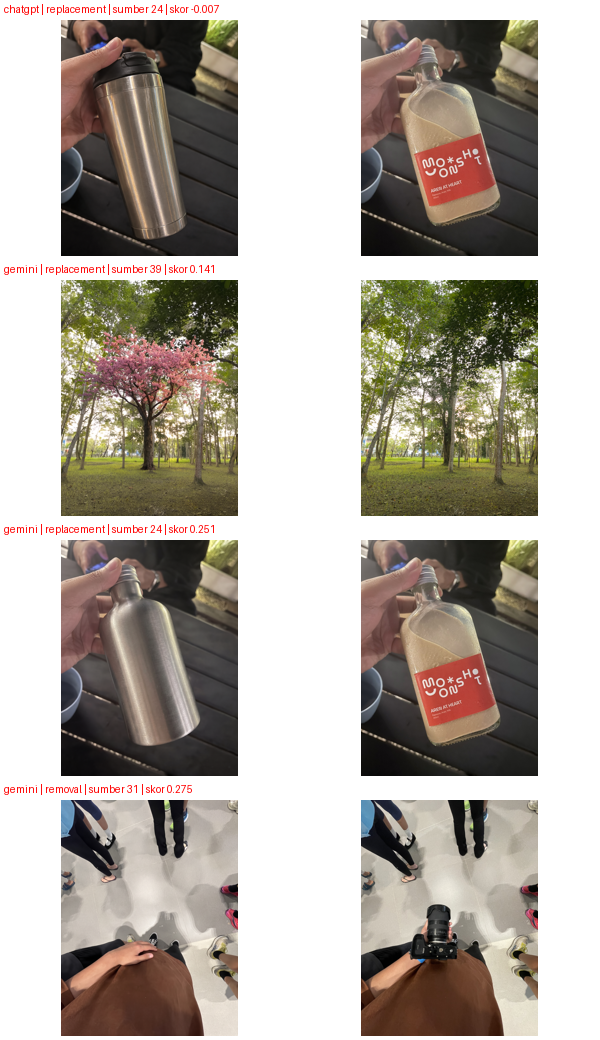


Tersimpan di: /content/drive/MyDrive/PROJECT JURNAL - JATIKARYA/JATIKARYA_NEW/07_ANALYSIS_V2


In [ ]:
# SEL 7 - AUDIT DISTRAKTOR + GAMBAR GENUINE YANG GAGAL
from collections import Counter
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

def meta(p):
    with Image.open(p) as im:
        ex = im.getexif()
        w, h = im.size
    return {"w": w, "h": h, "mp": w * h / 1e6, "kb": p.stat().st_size / 1024,
            "make": str(ex.get(271, "")).strip(), "model": str(ex.get(272, "")).strip(),
            "ada_exif": len(ex) > 0}

def ringkas(paths, judul):
    df = pd.DataFrame([meta(p) for p in paths])
    print(f"\n=== {judul} (n={len(df)}) ===")
    print("Dengan EXIF :", int(df.ada_exif.sum()), "| tanpa EXIF:", int((~df.ada_exif).sum()))
    print("Kamera      :", dict(Counter((df.make + " " + df.model).str.strip()).most_common(5)))
    print("Megapiksel  : min %.2f | median %.2f | maks %.2f" % (df.mp.min(), df.mp.median(), df.mp.max()))
    print("Ukuran file : min %.0f KB | median %.0f KB | maks %.0f KB" % (df.kb.min(), df.kb.median(), df.kb.max()))
    print("File < 0.5 MP:", int((df.mp < 0.5).sum()), "| < 100 KB:", int((df.kb < 100).sum()))
    return df

d_dist = ringkas(files, "DISTRAKTOR")
d_src = ringkas([BASE / p for p in S.stored_path], "40 SUMBER")
d_dist.to_csv(OUT / "distractor_metadata.csv", index=False)

# Lembar kontak 30 distraktor acak
rng = np.random.default_rng(3)
pick = rng.choice(len(files), 30, replace=False)
T, C = 200, 6
sheet = Image.new("RGB", (C * T, 5 * (T + 18)), "white")
dr = ImageDraw.Draw(sheet)
for k, i in enumerate(pick):
    im = ImageOps.contain(load(files[i]), (T - 8, T - 8))
    x, y = (k % C) * T, (k // C) * (T + 18)
    sheet.paste(im, (x + (T - im.width) // 2, y + 16))
    dr.text((x + 4, y + 2), f"{i}: {files[i].name[:22]}", fill="red")
sheet.save(OUT / "distractor_contact_sheet.jpg", quality=88)
display(sheet)

# Gambar genuine dengan skor sumber-benar terendah (semua metode)
n0 = "DINOv2-S crop (lama)"
gen = full[n0][np.arange(len(G)), true_idx]
worst = np.argsort(gen)[:6]
tab = G.iloc[worst][["provider", "edit_type", "source_number", "split"]].copy()
tab["skor_sumber_benar"] = gen[worst].round(3)
tab["top1_benar"] = full[n0][worst].argmax(1) == true_idx[worst]
print("\n=== 6 gambar genuine dengan skor terendah (%s) ===" % n0)
print(tab.to_string())
tab.to_csv(OUT / "worst_genuine_queries.csv", index=False)

# Pasangan: kiri = gambar edit AI, kanan = sumber aslinya
W2, H2 = 300, 260
pair = Image.new("RGB", (W2 * 2, H2 * 4), "white")
dp = ImageDraw.Draw(pair)
for r_, i in enumerate(worst[:4]):
    for c_, im in enumerate([qry_imgs[i], src_imgs[true_idx[i]]]):
        im = ImageOps.contain(im, (W2 - 8, H2 - 24))
        pair.paste(im, (c_ * W2 + (W2 - im.width) // 2, r_ * H2 + 20))
    dp.text((4, r_ * H2 + 3),
            f"{G.provider.iloc[i]} | {G.edit_type.iloc[i]} | sumber {G.source_number.iloc[i]} | skor {gen[i]:.3f}",
            fill="red")
pair.save(OUT / "worst_genuine_pairs.jpg", quality=88)
display(pair)
print("\nTersimpan di:", OUT)

In [ ]:
# SEL 8 - UJI SENSITIVITAS: DISTRAKTOR >= 1.0 MP (aturan ditetapkan sebelum melihat hasil)
assert len(dist_imgs) == len(files) == len(d_dist), "Urutan distraktor tidak sejajar"
mask_big = d_dist.mp.values >= 1.0
print("Distraktor >= 1.0 MP:", int(mask_big.sum()), "dari", len(mask_big))
print("Dengan EXIF di subset:", int(d_dist.ada_exif.values[mask_big].sum()))

r = np.arange(len(G))
rng = np.random.default_rng(2)
rows = []
for n in names:
    gen = full[n][r, true_idx]
    g_f = gen[fin]
    thr = float(np.quantile(gen[cal], 0.05))        # ambang CALIBRATION, retensi 95%
    for label, m in [("semua distraktor", np.ones(len(mask_big), bool)),
                     (">= 1.0 MP", mask_big)]:
        fo = foreign_scores[n][m]
        bs = []
        for _ in range(1000):
            pick = rng.choice(srcs, len(srcs), replace=True)
            gi = np.concatenate([idx_by_src[s] for s in pick])
            fi = rng.integers(0, len(fo), len(fo))
            bs.append(auc(g_f[gi], fo[fi]))
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append({"metode": n, "distraktor": label, "n_asing": int(m.sum()),
                     "AUC_final": round(auc(g_f, fo), 3),
                     "AUC_CI95": [round(lo, 3), round(hi, 3)],
                     "FAR_ambang_CAL95": round(float((fo >= thr).mean()), 3)})
    print("selesai:", n)

res5 = pd.DataFrame(rows)
print(res5.to_string(index=False))
res5.to_csv(OUT / "sensitivity_distractor_resolution.csv", index=False)
print("Tersimpan di:", OUT / "sensitivity_distractor_resolution.csv")

Distraktor >= 1.0 MP: 64 dari 120
Dengan EXIF di subset: 59
selesai: pHash
selesai: CLIP-B32
selesai: DINOv2-S crop (lama)
selesai: DINOv2-S tanpa crop
selesai: DINOv2-B tanpa crop
              metode       distraktor  n_asing  AUC_final     AUC_CI95  FAR_ambang_CAL95
               pHash semua distraktor      120      0.967 [0.901, 1.0]             0.000
               pHash        >= 1.0 MP       64      0.967 [0.901, 1.0]             0.000
            CLIP-B32 semua distraktor      120      0.996 [0.986, 1.0]             0.000
            CLIP-B32        >= 1.0 MP       64      0.996 [0.986, 1.0]             0.000
DINOv2-S crop (lama) semua distraktor      120      0.995 [0.984, 1.0]             0.208
DINOv2-S crop (lama)        >= 1.0 MP       64      0.995 [0.984, 1.0]             0.172
 DINOv2-S tanpa crop semua distraktor      120      0.997 [0.992, 1.0]             0.092
 DINOv2-S tanpa crop        >= 1.0 MP       64      0.998 [0.992, 1.0]             0.094
 DINOv2-B tanpa cr

In [ ]:
%pip -q install imagehash

In [ ]:
import sys, numpy, pandas, PIL, torch, torchvision, transformers, sklearn, imagehash
from importlib.metadata import version
print("python", sys.version.split()[0])
for n in ["numpy","pandas","pillow","torch","torchvision","transformers","scikit-learn","imagehash","trustmark"]:
    try: print(n, version(n))
    except Exception as e: print(n, "TIDAK TERPASANG")

python 3.13.16
numpy 2.4.6
pandas 2.2.3
pillow 11.3.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
transformers 5.22.1
scikit-learn 1.6.1
imagehash 4.3.2
trustmark TIDAK TERPASANG
